In [1]:
# ============================================================
# STEP 1: SET PERSONAL PARAMETERS AND RANDOM SEEDS
# ============================================================

# Block 1: Import the libraries used for random numbers and PyTorch.
import random
import numpy as np
import torch

# Block 2: Calculate the personal parameters from your student ID.
SID4 = 1980
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Block 3: Set the same seed across Python, NumPy, and PyTorch.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Block 4: Print the values to verify them.
print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, "
      f"HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

SID4=1980, SEED=1980, SLICE=980, HP_ID=0, CLS_A=0, CLS_B=1
Device: cuda


In [4]:
# ============================================================
# STEP 2: LOAD THE SHAKESPEARE DATASET FROM GOOGLE DRIVE
# ============================================================

# Block 1: Connect Colab to your Google Drive.
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

# Block 2: Use the folder and filename shown in your screenshot.
data_path = Path("/content/drive/MyDrive/GEN AI HWS/HW4/shakespeare.txt")

# Block 3: Check the path so an incorrect folder name is easy to spot.
if not data_path.is_file():
    raise FileNotFoundError(f"File not found at: {data_path}")

# Block 4: Read the text, keeping spaces and line breaks.
text = data_path.read_text(encoding="utf-8")

# Block 5: Verify that the dataset loaded.
print("File:", data_path.name)
print("Total characters:", len(text))
print("First 300 characters:")
print(repr(text[:300]))

Mounted at /content/drive
File: shakespeare.txt
Total characters: 1738
First 300 characters:
'ROMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the envious moon,\nWho is already sick and pale with grief,\nThat thou her maid art far more fair than she.\nBe not her maid, since she is envious;\nHer vestal livery is but sick a'


In [5]:
# ============================================================
# STEP 3: CREATE THE CHARACTER-LEVEL TOKENIZER
# ============================================================

# Block 1: Collect every unique character in the text.
# Sorting gives the same character-to-number mapping on every run.
chars = sorted(set(text))
vocab_size = len(chars)

# Block 2: Create mappings in both directions.
char_to_idx = {char: idx for idx, char in enumerate(chars)}
idx_to_char = {idx: char for idx, char in enumerate(chars)}

# Block 3: Convert text to token numbers and back.
def encode(s):
    return [char_to_idx[char] for char in s]

def decode(indices):
    return "".join(idx_to_char[int(idx)] for idx in indices)

# Block 4: Check the vocabulary and verify a round trip.
sample = text[:60]
print("Vocabulary size:", vocab_size)
print("Encoded sample:", encode(sample))
print("Decoded sample:", repr(decode(encode(sample))))

assert decode(encode(sample)) == sample

Vocabulary size: 49
Encoded sample: [20, 19, 17, 12, 19, 5, 0, 9, 43, 42, 3, 1, 41, 38, 30, 42, 2, 1, 45, 32, 25, 42, 1, 35, 33, 31, 32, 42, 1, 42, 32, 40, 38, 43, 31, 32, 1, 46, 38, 37, 28, 29, 40, 1, 45, 33, 37, 28, 38, 45, 1, 26, 40, 29, 25, 34, 41, 7, 0, 14]
Decoded sample: 'ROMEO:\nBut, soft! what light through yonder window breaks?\nI'


In [7]:
# ============================================================
# STEP 4: CREATE THE SLIDING WINDOW DATASET
#What this step does: Each input contains 128 characters. Its target contains the next 128 characters, shifted one position forward. This teaches the model to predict the next character at every position.
# ============================================================

# Block 1: Convert the complete text to a PyTorch tensor.
sequence_length = 128
tokens = torch.tensor(encode(text), dtype=torch.long)

# Block 2: Define a dataset that moves one character at a time.
class ShakespeareDataset(torch.utils.data.Dataset):
    def __init__(self, token_ids, sequence_length):
        self.token_ids = token_ids
        self.sequence_length = sequence_length

    def __len__(self):
        # Each example needs 128 input tokens plus one next token.
        return len(self.token_ids) - self.sequence_length

    def __getitem__(self, index):
        x = self.token_ids[index : index + self.sequence_length]
        y = self.token_ids[index + 1 : index + self.sequence_length + 1]
        return x, y

# Block 3: Create the dataset and check its size.
dataset = ShakespeareDataset(tokens, sequence_length)
print("Number of input–target pairs:", len(dataset))

# Block 4: Decode and display two example pairs.
for example_number, index in enumerate([0, 1], start=1):
    x, y = dataset[index]

    print(f"\nExample {example_number}")
    print("Input: ", repr(decode(x)))
    print("Target:", repr(decode(y)))

    # The target must be the input shifted forward by one character.
    assert torch.equal(x[1:], y[:-1])

Number of input–target pairs: 1610

Example 1
Input:  'ROMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the '
Target: 'OMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the e'

Example 2
Input:  'OMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the e'
Target: 'MEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the en'


In [8]:
# ============================================================
# STEP 5: IMPLEMENT MASKED MULTI-HEAD SELF-ATTENTION
#What this step does: Each character can attend to characters at its own position and earlier positions. The causal mask prevents it from seeing future characters.
# ============================================================

import math
import torch.nn as nn

# Block 1: Set model dimensions.
hidden_dim = 128
num_heads = 4

assert hidden_dim % num_heads == 0
head_dim = hidden_dim // num_heads

# Block 2: Build attention manually using Linear layers.
class MaskedMultiHeadAttention(nn.Module):
    def __init__(self, hidden_dim, num_heads):
        super().__init__()

        assert hidden_dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads

        # Separate learned projections for queries, keys, and values.
        self.query = nn.Linear(hidden_dim, hidden_dim)
        self.key = nn.Linear(hidden_dim, hidden_dim)
        self.value = nn.Linear(hidden_dim, hidden_dim)

        # Combine information from all heads.
        self.output = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x):
        batch_size, seq_len, hidden_dim = x.shape

        # Block 3: Project and split into attention heads.
        # Shape: (batch, heads, sequence, head_dim)
        q = self.query(x).view(
            batch_size, seq_len, self.num_heads, self.head_dim
        ).transpose(1, 2)

        k = self.key(x).view(
            batch_size, seq_len, self.num_heads, self.head_dim
        ).transpose(1, 2)

        v = self.value(x).view(
            batch_size, seq_len, self.num_heads, self.head_dim
        ).transpose(1, 2)

        # Block 4: Calculate scaled attention scores.
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # Block 5: Mask future positions before softmax.
        # True means the position is in the future and must be hidden.
        future_mask = torch.triu(
            torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool),
            diagonal=1
        )
        scores = scores.masked_fill(future_mask, float("-inf"))

        # Block 6: Turn scores into weights and combine the values.
        weights = torch.softmax(scores, dim=-1)
        attended = weights @ v

        # Block 7: Join the heads and apply the output projection.
        attended = attended.transpose(1, 2).contiguous()
        attended = attended.view(batch_size, seq_len, hidden_dim)

        return self.output(attended)

# Block 8: Check that the output shape matches the input shape.
attention = MaskedMultiHeadAttention(hidden_dim, num_heads)
test_input = torch.randn(2, sequence_length, hidden_dim)
test_output = attention(test_input)

print("Input shape: ", tuple(test_input.shape))
print("Output shape:", tuple(test_output.shape))
print("Number of heads:", num_heads)

assert test_output.shape == test_input.shape

Input shape:  (2, 128, 128)
Output shape: (2, 128, 128)
Number of heads: 4


In [9]:
# ============================================================
# STEP 6: BUILD A TRANSFORMER DECODER BLOCK
#Adds a residual connection and LayerNorm around attention, then another residual connection and LayerNorm around a feedforward network.
# ============================================================

# Block 1: Define one decoder block.
class DecoderBlock(nn.Module):
    def __init__(self, hidden_dim, num_heads):
        super().__init__()

        # Attention and its normalization layer.
        self.attention = MaskedMultiHeadAttention(hidden_dim, num_heads)
        self.norm1 = nn.LayerNorm(hidden_dim)

        # Feedforward network and its normalization layer.
        self.feedforward = nn.Sequential(
            nn.Linear(hidden_dim, 4 * hidden_dim),
            nn.GELU(),
            nn.Linear(4 * hidden_dim, hidden_dim)
        )
        self.norm2 = nn.LayerNorm(hidden_dim)

    def forward(self, x):
        # Block 2: Attention → residual addition → LayerNorm.
        x = self.norm1(x + self.attention(x))

        # Block 3: Feedforward → residual addition → LayerNorm.
        x = self.norm2(x + self.feedforward(x))

        return x

# Block 4: Verify that the block preserves the tensor shape.
decoder_block = DecoderBlock(hidden_dim, num_heads)
block_output = decoder_block(test_input)

print("Input shape: ", tuple(test_input.shape))
print("Output shape:", tuple(block_output.shape))

assert block_output.shape == test_input.shape

Input shape:  (2, 128, 128)
Output shape: (2, 128, 128)


In [10]:
# ============================================================
# STEP 7: BUILD THE DECODER-ONLY GPT MODEL
# Turns character IDs into embeddings, adds learned position embeddings, passes them through 2 decoder blocks, and predicts a score for every character in the vocabulary.
# ============================================================

# Block 1: Set the number of decoder blocks.
num_layers = 2

# Block 2: Define the complete model.
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, hidden_dim, num_heads,
                 num_layers, sequence_length):
        super().__init__()

        self.sequence_length = sequence_length

        # Convert character IDs and positions into vectors.
        self.token_embedding = nn.Embedding(vocab_size, hidden_dim)
        self.position_embedding = nn.Embedding(sequence_length, hidden_dim)

        # Stack multiple decoder blocks.
        self.blocks = nn.Sequential(*[
            DecoderBlock(hidden_dim, num_heads)
            for _ in range(num_layers)
        ])

        # Convert each final vector into vocabulary scores (logits).
        self.output_projection = nn.Linear(hidden_dim, vocab_size)

    def forward(self, token_ids):
        batch_size, seq_len = token_ids.shape

        if seq_len > self.sequence_length:
            raise ValueError(
                f"Input length {seq_len} exceeds {self.sequence_length}"
            )

        # Block 3: Add token and learnable positional embeddings.
        positions = torch.arange(seq_len, device=token_ids.device)
        x = (
            self.token_embedding(token_ids)
            + self.position_embedding(positions)
        )

        # Block 4: Process the sequence and produce vocabulary logits.
        x = self.blocks(x)
        logits = self.output_projection(x)

        return logits

# Block 5: Create the model on the GPU if available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MiniGPT(
    vocab_size=vocab_size,
    hidden_dim=hidden_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    sequence_length=sequence_length
).to(device)

# Block 6: Print the architecture details required by the assignment.
total_parameters = sum(p.numel() for p in model.parameters())

print("Device:", device)
print("Total parameters:", f"{total_parameters:,}")
print("Hidden dimension:", hidden_dim)
print("Number of heads:", num_heads)
print("Number of layers:", num_layers)

# Block 7: Verify the output shape with one real dataset example.
example_x, _ = dataset[0]
example_logits = model(example_x.unsqueeze(0).to(device))

print("Logits shape:", tuple(example_logits.shape))
assert example_logits.shape == (1, sequence_length, vocab_size)

Device: cuda
Total parameters: 425,521
Hidden dimension: 128
Number of heads: 4
Number of layers: 2
Logits shape: (1, 128, 49)


In [11]:
# ============================================================
# STEP 8: TRAIN THE MINI GPT MODEL
# ============================================================

import time

# Block 1: Choose the training settings.
batch_size = 32
learning_rate = 3e-4
num_epochs = 6

# Shuffle training examples using your assigned seed.
train_generator = torch.Generator().manual_seed(SEED)
train_loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=train_generator
)

# Block 2: Set up Adam and the next-character loss.
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss_function = nn.CrossEntropyLoss()

# Keep one average loss per epoch for the required plot.
epoch_losses = []

# Block 3: Train for six complete passes over the dataset.
model.train()
for epoch in range(num_epochs):
    start_time = time.time()
    total_loss = 0.0
    total_examples = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        # Predict a vocabulary score at every sequence position.
        optimizer.zero_grad()
        logits = model(inputs)

        # CrossEntropyLoss expects (positions, vocabulary size)
        # and one correct character ID per position.
        loss = loss_function(
            logits.reshape(-1, vocab_size),
            targets.reshape(-1)
        )

        # Update the model parameters.
        loss.backward()
        optimizer.step()

        # Weight the batch loss by its number of examples.
        total_loss += loss.item() * inputs.size(0)
        total_examples += inputs.size(0)

    # Block 4: Record and display the average epoch loss.
    average_loss = total_loss / total_examples
    epoch_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {average_loss:.4f} | "
        f"Time: {time.time() - start_time:.1f}s",
        flush=True
    )

Epoch 1/6 | Loss: 3.0354 | Time: 0.8s
Epoch 2/6 | Loss: 2.4151 | Time: 0.4s
Epoch 3/6 | Loss: 2.2322 | Time: 0.4s
Epoch 4/6 | Loss: 2.1379 | Time: 0.4s
Epoch 5/6 | Loss: 2.0589 | Time: 0.4s
Epoch 6/6 | Loss: 1.9780 | Time: 0.4s


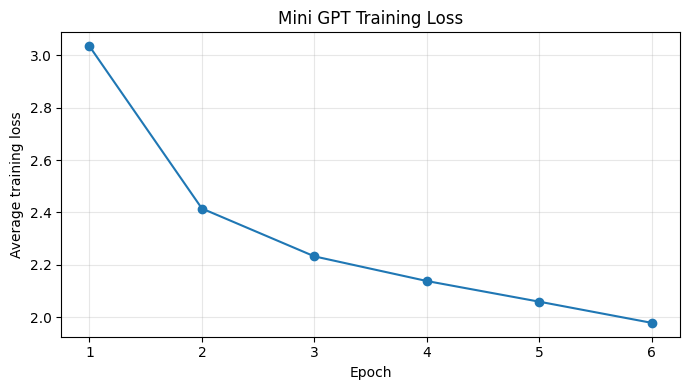

Saved figure to: /content/drive/MyDrive/GEN AI HWS/HW4/training_loss.png


In [12]:
# ============================================================
# STEP 9: PLOT AND SAVE THE TRAINING LOSS CURVE
# ============================================================

import matplotlib.pyplot as plt

# Block 1: Create one point for each completed epoch.
epochs = range(1, len(epoch_losses) + 1)

# Block 2: Draw the loss curve.
plt.figure(figsize=(7, 4))
plt.plot(epochs, epoch_losses, marker="o")
plt.title("Mini GPT Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.xticks(list(epochs))
plt.grid(alpha=0.3)
plt.tight_layout()

# Block 3: Save the figure in your HW4 folder, then display it.
figure_path = data_path.parent / "training_loss.png"
plt.savefig(figure_path, dpi=200)
plt.show()

print("Saved figure to:", figure_path)

In [13]:
# ============================================================
# STEP 10: SAVE THE TRAINED MODEL CHECKPOINT
# ============================================================

# Block 1: Choose a permanent location beside shakespeare.txt.
checkpoint_path = data_path.parent / "mini_gpt_checkpoint.pt"

# Block 2: Save weights and everything needed to rebuild the model.
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocab_size": vocab_size,
        "chars": chars,
        "hidden_dim": hidden_dim,
        "num_heads": num_heads,
        "num_layers": num_layers,
        "sequence_length": sequence_length,
        "seed": SEED,
        "epoch_losses": epoch_losses,
    },
    checkpoint_path
)

# Block 3: Verify that the file was created.
print("Checkpoint saved:", checkpoint_path)
print("File size:", round(checkpoint_path.stat().st_size / (1024 * 1024), 2), "MB")

assert checkpoint_path.is_file()

Checkpoint saved: /content/drive/MyDrive/GEN AI HWS/HW4/mini_gpt_checkpoint.pt
File size: 1.64 MB


In [14]:
# ============================================================
# STEP 11: GENERATE TEXT WITH GREEDY DECODING
#Starts with ROMEO: and repeatedly selects the character with the highest predicted score.
# ============================================================

# Block 1: Define greedy generation.
@torch.no_grad()
def generate_greedy(model, prompt, max_new_chars=200):
    model.eval()

    # Convert the prompt to character IDs.
    generated = torch.tensor(
        [encode(prompt)], dtype=torch.long, device=device
    )

    # Block 2: Predict one new character at a time.
    for _ in range(max_new_chars):
        # The model can read at most 128 characters at once.
        context = generated[:, -sequence_length:]

        # Take the scores for the next character.
        logits = model(context)[:, -1, :]

        # Greedy decoding chooses the highest-scoring character.
        next_token = torch.argmax(logits, dim=-1, keepdim=True)
        generated = torch.cat((generated, next_token), dim=1)

    # Block 3: Convert the result back to readable text.
    return decode(generated[0].tolist())

# Block 4: Generate the required sample.
greedy_text = generate_greedy(model, "ROMEO:", max_new_chars=200)

print("GREEDY DECODING")
print(greedy_text)

GREEDY DECODING
ROMEO:
Romeor the that that that t t the the theee thy whe thee whe whe the the the woullll we whe woul wil wee whe whe we willl we wit the wit the withe the with the the t t theathe thith t t th th th the 


In [15]:
# ============================================================
# STEP 12: GENERATE TEXT WITH TEMPERATURE SAMPLING
# ============================================================

# Block 1: Define temperature-based generation.
@torch.no_grad()
def generate_temperature(model, prompt, temperature, max_new_chars=200):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    model.eval()
    generated = torch.tensor(
        [encode(prompt)], dtype=torch.long, device=device
    )

    # Reset the sampling seed for a repeatable comparison.
    sample_generator = torch.Generator(device=device).manual_seed(SEED)

    # Block 2: Sample one character at a time.
    for _ in range(max_new_chars):
        context = generated[:, -sequence_length:]
        logits = model(context)[:, -1, :]

        # Lower temperature sharpens the probabilities;
        # higher temperature spreads them out.
        probabilities = torch.softmax(logits / temperature, dim=-1)

        next_token = torch.multinomial(
            probabilities, num_samples=1, generator=sample_generator
        )
        generated = torch.cat((generated, next_token), dim=1)

    # Block 3: Decode the generated character IDs.
    return decode(generated[0].tolist())

# Block 4: Generate and save all three results for later analysis.
temperature_outputs = {}

for temperature in [0.5, 1.0, 1.5]:
    generated_text = generate_temperature(
        model, "ROMEO:", temperature=temperature
    )
    temperature_outputs[temperature] = generated_text

    print(f"\nTEMPERATURE = {temperature}")
    print(generated_text)


TEMPERATURE = 0.5
ROMEO:
He tat me
By f Romeome t t neout thathe t har nor nome whe at nouthout nd the or ame ir thame n ame iThoull wiss t the the,


Ro t me!
T:
Tout t no t at anome neeame;
Tal o at te he.
By the thy thes 

TEMPERATURE = 1.0
ROMEO:
He but me
Anof RO:
Whany t ne, owhome be thar ne
JULJULIET:

: buthy at nou t ort normertoue
Romet naThar n amesmy thaptho, the whome!
T:
Rout peomer us anyeesueeame;
Sheme :
Whe he.
Bef.
Ow fat ath 

TEMPERATURE = 1.5
ROMEO:
Hepukesme
An f RO:
RO.
I t nenk wholf bu’ htha ny paJo ’:
O,.: iomescat nomeg orf ntBye
Aome
u metam?Thasck ape’ny thapcarel tl where!ULI’souzeJU
Her us ankingueeame; rmemo :
W
e he.
Hef.
OwMo?
’t s 


In [16]:
# ============================================================
# STEP 13: GENERATE TEXT WITH TOP-K SAMPLING
# ============================================================

# Block 1: Define top-k generation.
@torch.no_grad()
def generate_top_k(model, prompt, k, max_new_chars=200):
    if not 1 <= k <= vocab_size:
        raise ValueError(f"k must be between 1 and {vocab_size}.")

    model.eval()
    generated = torch.tensor(
        [encode(prompt)], dtype=torch.long, device=device
    )

    # Use the same seed for a repeatable comparison.
    sample_generator = torch.Generator(device=device).manual_seed(SEED)

    # Block 2: Select and sample from the top k characters.
    for _ in range(max_new_chars):
        context = generated[:, -sequence_length:]
        logits = model(context)[:, -1, :]

        top_scores, top_indices = torch.topk(logits, k=k, dim=-1)
        top_probabilities = torch.softmax(top_scores, dim=-1)

        # Sample a position among the top k, then find its character ID.
        chosen_position = torch.multinomial(
            top_probabilities, num_samples=1, generator=sample_generator
        )
        next_token = top_indices.gather(dim=-1, index=chosen_position)

        generated = torch.cat((generated, next_token), dim=1)

    # Block 3: Decode the complete result.
    return decode(generated[0].tolist())

# Block 4: Generate and retain both outputs for the analysis.
top_k_outputs = {}

for k in [3, 20]:
    generated_text = generate_top_k(model, "ROMEO:", k=k)
    top_k_outputs[k] = generated_text

    print(f"\nTOP-K = {k}")
    print(generated_text)


TOP-K = 3
ROMEO:
Romeat theor thou an nore nousere theatind me wher t win t t t t at worelor amer nore ther whouthe t t t t wono nde nand whath willllouthellllll we t
Bear we bear wo wo bere we t we bel belld,



T:


TOP-K = 20
ROMEO:
RLI now te bat sht t’onor nonotheat s: ise at inoume;
Roff anthy woffather ell be, h’d t.
Whamere t f me in wherthom;
T:
JULIE
He, t wo, that tl t tho, nowhathathan but w am, is t ldetw s at m, t no 


## Step 14 — Decoding comparison and analysis

| Method | Observation from my generated text |
|---|---|
| Greedy | Repeated common fragments such as “the” and “whe”; limited variety. |
| Temperature 0.5 | More familiar character patterns, but still repetitive. |
| Temperature 1.0 | More variation, including a recognizable speaker label, but many malformed words. |
| Temperature 1.5 | The most varied temperature output, with unusual punctuation and character combinations; less readable. |
| Top-k 3 | Restricted choices led to repetition, including “t t t t” and “hellllll.” |
| Top-k 20 | More varied words, punctuation, and speaker labels than top-k 3, though the text remains fragmented. |

**Most coherent:** Of these samples, I judge [choose the output you find easiest to read] the most coherent because [cite a specific phrase or pattern]. None produced a consistently coherent passage.

**Most diverse:** Temperature 1.5 produced the widest variety of character combinations and punctuation, though much of that variety reduced readability. Top-k 20 was more diverse than top-k 3.

**Limitation:** The training file was small, so the model learned some Shakespeare-like character patterns without reliably forming meaningful dialogue. These conclusions describe the samples generated in this run.

In [17]:
# ============================================================
# STEP 15: SAVE TRAINING METRICS
# ============================================================

# Block 1: Build a Markdown table from the recorded epoch losses.
loss_rows = "\n".join(
    f"| {epoch} | {loss:.4f} |"
    for epoch, loss in enumerate(epoch_losses, start=1)
)

# Block 2: Include the model settings and required measurements.
metrics_text = f"""# HW4 — Mini GPT Metrics

## Model and training settings

| Measurement | Value |
|---|---:|
| SID4 / seed | {SID4} |
| Vocabulary size | {vocab_size} |
| Sequence length | {sequence_length} |
| Hidden dimension | {hidden_dim} |
| Attention heads | {num_heads} |
| Decoder layers | {num_layers} |
| Total parameters | {total_parameters:,} |
| Batch size | {batch_size} |
| Adam learning rate | {learning_rate} |
| Epochs | {num_epochs} |

## Training loss

| Epoch | Average training loss |
|---:|---:|
{loss_rows}

## Decoding settings

Prompt: `ROMEO:`; generated characters: 200 per output.

| Method | Settings |
|---|---|
| Greedy | Highest-scoring character |
| Temperature | 0.5, 1.0, 1.5 |
| Top-k | 3, 20 |
"""

# Block 3: Save the file beside your checkpoint and figure.
metrics_path = data_path.parent / "METRICS.md"
metrics_path.write_text(metrics_text, encoding="utf-8")

print("Saved:", metrics_path)
print(metrics_text)

Saved: /content/drive/MyDrive/GEN AI HWS/HW4/METRICS.md
# HW4 — Mini GPT Metrics

## Model and training settings

| Measurement | Value |
|---|---:|
| SID4 / seed | 1980 |
| Vocabulary size | 49 |
| Sequence length | 128 |
| Hidden dimension | 128 |
| Attention heads | 4 |
| Decoder layers | 2 |
| Total parameters | 425,521 |
| Batch size | 32 |
| Adam learning rate | 0.0003 |
| Epochs | 6 |

## Training loss

| Epoch | Average training loss |
|---:|---:|
| 1 | 3.0354 |
| 2 | 2.4151 |
| 3 | 2.2322 |
| 4 | 2.1379 |
| 5 | 2.0589 |
| 6 | 1.9780 |

## Decoding settings

Prompt: `ROMEO:`; generated characters: 200 per output.

| Method | Settings |
|---|---|
| Greedy | Highest-scoring character |
| Temperature | 0.5, 1.0, 1.5 |
| Top-k | 3, 20 |



In [18]:
# ============================================================
# STEP 16: CREATE THE FINDINGS PDF
#Saves a PDF with your model settings, loss curve, sample excerpts, and decoding analysis. Based on the outputs you shared, this draft identifies temperature 1.0 as the most coherent sample and temperature 1.5 as the most diverse. Read the wording before submitting so it reflects your own assessment.
# ============================================================

import textwrap
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Block 1: Set the output location.
pdf_path = data_path.parent / "HW4_Mini_GPT_Findings.pdf"

# Block 2: Prepare short excerpts from the actual generated outputs.
samples = [
    ("Greedy", greedy_text),
    ("Temperature 0.5", temperature_outputs[0.5]),
    ("Temperature 1.0", temperature_outputs[1.0]),
    ("Temperature 1.5", temperature_outputs[1.5]),
    ("Top-k 3", top_k_outputs[3]),
    ("Top-k 20", top_k_outputs[20]),
]

def excerpt(s, length=105):
    # Show line breaks visibly so each excerpt fits in the report.
    return repr(s[:length])

# Block 3: Create a two-page PDF.
with PdfPages(pdf_path) as pdf:

    # PAGE 1: Model details and training curve.
    fig, ax = plt.subplots(figsize=(8.5, 11))
    ax.axis("off")

    details = (
        f"HW4: Mini GPT from Scratch\n\n"
        f"SID4: {SID4}    Seed: {SEED}\n"
        f"Vocabulary: {vocab_size} characters    Sequence length: {sequence_length}\n"
        f"Hidden dimension: {hidden_dim}    Heads: {num_heads}\n"
        f"Decoder blocks: {num_layers}    Parameters: {total_parameters:,}\n"
        f"Optimizer: Adam    Learning rate: {learning_rate}\n"
        f"Batch size: {batch_size}    Epochs: {num_epochs}\n\n"
        f"Training loss decreased from {epoch_losses[0]:.4f} "
        f"to {epoch_losses[-1]:.4f}."
    )
    ax.text(0.08, 0.94, details, va="top", fontsize=12,
            linespacing=1.6, transform=ax.transAxes)

    curve_ax = fig.add_axes([0.15, 0.18, 0.72, 0.34])
    curve_ax.plot(range(1, num_epochs + 1), epoch_losses, marker="o")
    curve_ax.set_title("Average training loss by epoch")
    curve_ax.set_xlabel("Epoch")
    curve_ax.set_ylabel("Training loss")
    curve_ax.set_xticks(range(1, num_epochs + 1))
    curve_ax.grid(alpha=0.3)

    pdf.savefig(fig)
    plt.close(fig)

    # PAGE 2: Output excerpts and findings.
    fig, ax = plt.subplots(figsize=(8.5, 11))
    ax.axis("off")

    lines = ["Decoding comparison", "", "Prompt: ROMEO:", ""]
    for label, result in samples:
        lines.append(label + ":")
        lines.extend(textwrap.wrap(excerpt(result), width=82))
        lines.append("")

    lines.extend([
        "Findings",
        "Greedy decoding repeatedly chose common fragments such as 'the' and 'whe'.",
        "Temperature 0.5 remained repetitive. Temperature 1.0 produced some",
        "recognizable dialogue cues. Temperature 1.5 introduced the widest range",
        "of character combinations and punctuation, but was less readable.",
        "Top-k 3 repeated fragments; top-k 20 allowed more varied output.",
        "",
        "Most coherent in these samples: temperature 1.0, because it includes",
        "recognizable speaker-like text, although the passage is still fragmented.",
        "Most diverse: temperature 1.5, at the cost of readability.",
        "",
        "Limitation: the small training text and six training epochs limit",
        "the model's ability to produce meaningful dialogue."
    ])

    ax.text(
        0.07, 0.96, "\n".join(lines),
        va="top", family="monospace", fontsize=8.5,
        linespacing=1.35, transform=ax.transAxes
    )

    pdf.savefig(fig)
    plt.close(fig)

# Block 4: Confirm that the PDF exists.
print("Saved findings PDF:", pdf_path)
print("Size:", round(pdf_path.stat().st_size / 1024, 1), "KB")

Saved findings PDF: /content/drive/MyDrive/GEN AI HWS/HW4/HW4_Mini_GPT_Findings.pdf
Size: 36.4 KB


# HW4 — AI Use

## 1. Which parts did I use an assistant for, and which did I do myself?

I used ChatGPT to help draft the PyTorch code for character tokenization, the sliding-window dataset, masked multi-head attention, the decoder blocks, training, and the three decoding methods. I ran each cell in Colab, checked its output, trained the model on the course Shakespeare file, and compared the generated samples myself.

## 2. What was one specific thing the assistant got wrong?

The assistant initially gave me a file path that assumed `Shakespeare.txt` had been uploaded directly to Colab:

`/content/Shakespeare.txt`

The cell failed with:

`FileNotFoundError: Shakespeare.txt was not found. Upload it using Colab's folder icon.`

My file was actually named `shakespeare.txt` and was stored in my Google Drive HW4 folder.

## 3. How did I find out?

I ran the dataset-loading cell and received the `FileNotFoundError`. I then checked where I had saved the file and confirmed its exact filename in Google Drive.

## 4. What did I change, and why does it work?

I mounted Google Drive and changed the path to:

`/content/drive/MyDrive/GEN AI HWS/HW4/shakespeare.txt`

The corrected cell read the file and printed its character count and a text preview. I also checked that the attention block preserved the shape `(2, 128, 128)`, the model produced logits of shape `(1, 128, 49)`, and training loss decreased from 3.0354 to 1.9780 over six epochs.

In [20]:
# ============================================================
# STEP 18: SAVE THE RUN LOG
# ============================================================

from datetime import datetime, timezone

# Block 1: Record the current time and runtime details.
log_lines = [
    "HW4 MINI GPT RUN LOG",
    f"Log created (UTC): {datetime.now(timezone.utc).isoformat()}",
    "Execution: Run all cells in the HW4 Colab notebook, top to bottom",
    f"PyTorch version: {torch.__version__}",
    f"Device: {device}",
    f"Dataset: {data_path}",
    "",
    "MODEL",
    f"Vocabulary size: {vocab_size}",
    f"Sequence length: {sequence_length}",
    f"Hidden dimension: {hidden_dim}",
    f"Attention heads: {num_heads}",
    f"Decoder layers: {num_layers}",
    f"Total parameters: {total_parameters:,}",
    "",
    "TRAINING",
    f"Optimizer: Adam; learning rate: {learning_rate}",
    f"Batch size: {batch_size}; epochs: {num_epochs}",
]

# Block 2: Add the loss recorded after each epoch.
for epoch, loss in enumerate(epoch_losses, start=1):
    log_lines.append(f"Epoch {epoch}/{num_epochs} | Loss: {loss:.4f}")

# Block 3: Record the saved outputs and any observed errors.
log_lines.extend([
    "",
    "OUTPUT FILES",
    f"Checkpoint: {checkpoint_path}",
    f"Loss figure: {figure_path}",
    f"Findings PDF: {pdf_path}",
    "",
    "EARLIER SETUP ERROR",
    "FileNotFoundError: Shakespeare.txt was not found at "
    "/content/Shakespeare.txt.",
    "Resolved by mounting Drive and reading the actual file at:",
    str(data_path),
])

# Block 4: Save and display the log.
run_log_path = data_path.parent / "RUN_LOG.txt"
run_log_path.write_text("\n".join(log_lines) + "\n", encoding="utf-8")

print("Saved:", run_log_path)
print(run_log_path.read_text(encoding="utf-8"))

Saved: /content/drive/MyDrive/GEN AI HWS/HW4/RUN_LOG.txt
HW4 MINI GPT RUN LOG
Log created (UTC): 2026-09-21T20:08:48.312718+00:00
Execution: Run all cells in the HW4 Colab notebook, top to bottom
PyTorch version: 2.11.0+cu128
Device: cuda
Dataset: /content/drive/MyDrive/GEN AI HWS/HW4/shakespeare.txt

MODEL
Vocabulary size: 49
Sequence length: 128
Hidden dimension: 128
Attention heads: 4
Decoder layers: 2
Total parameters: 425,521

TRAINING
Optimizer: Adam; learning rate: 0.0003
Batch size: 32; epochs: 6
Epoch 1/6 | Loss: 3.0354
Epoch 2/6 | Loss: 2.4151
Epoch 3/6 | Loss: 2.2322
Epoch 4/6 | Loss: 2.1379
Epoch 5/6 | Loss: 2.0589
Epoch 6/6 | Loss: 1.9780

OUTPUT FILES
Checkpoint: /content/drive/MyDrive/GEN AI HWS/HW4/mini_gpt_checkpoint.pt
Loss figure: /content/drive/MyDrive/GEN AI HWS/HW4/training_loss.png
Findings PDF: /content/drive/MyDrive/GEN AI HWS/HW4/HW4_Mini_GPT_Findings.pdf

EARLIER SETUP ERROR
FileNotFoundError: Shakespeare.txt was not found at /content/Shakespeare.txt.
Resolve

In [21]:
# ============================================================
# STEP 19: SAVE THE AI-USE APPENDIX
# ============================================================

# Block 1: Write the account of how AI helped with this assignment.
ai_use_text = """# HW4 — AI Use

## 1. Which parts did I use an assistant for, and which did I do myself?

I used ChatGPT to help draft the PyTorch code for character tokenization, the sliding-window dataset, masked multi-head attention, the decoder blocks, training, and the three decoding methods. I ran each cell in Colab, checked its output, trained the model on the course Shakespeare file, and compared the generated samples myself.

## 2. What was one specific thing the assistant got wrong?

The assistant initially gave me a file path that assumed `Shakespeare.txt` had been uploaded directly to Colab:

`/content/Shakespeare.txt`

The cell failed with:

`FileNotFoundError: Shakespeare.txt was not found. Upload it using Colab's folder icon.`

My file was actually named `shakespeare.txt` and was stored in my Google Drive HW4 folder.

## 3. How did I find out?

I ran the dataset-loading cell and received the `FileNotFoundError`. I then checked where I had saved the file and confirmed its exact filename in Google Drive.

## 4. What did I change, and why does it work?

I mounted Google Drive and changed the path to:

`/content/drive/MyDrive/GEN AI HWS/HW4/shakespeare.txt`

The corrected cell read the file and printed its character count and a text preview. I also checked that the attention block preserved the shape `(2, 128, 128)`, the model produced logits of shape `(1, 128, 49)`, and training loss decreased from 3.0354 to 1.9780 over six epochs.
"""

# Block 2: Save the Markdown file beside the other HW4 artifacts.
ai_use_path = data_path.parent / "AI_USE.md"
ai_use_path.write_text(ai_use_text, encoding="utf-8")

# Block 3: Confirm that the file exists.
print("Saved:", ai_use_path)
assert ai_use_path.is_file()

Saved: /content/drive/MyDrive/GEN AI HWS/HW4/AI_USE.md


In [22]:
# ============================================================
# STEP 20: AUDIT THE HW4 SUBMISSION FILES
# ============================================================

# Block 1: Point to the folder containing your HW4 work.
hw4_folder = data_path.parent

required_files = [
    "HW4_Mini_GPT.ipynb",
    "shakespeare.txt",
    "HW4_Mini_GPT_Findings.pdf",
    "METRICS.md",
    "RUN_LOG.txt",
    "AI_USE.md",
    "mini_gpt_checkpoint.pt",
    "training_loss.png",
]

# Block 2: Report whether each file exists and has content.
missing_files = []

for filename in required_files:
    file_path = hw4_folder / filename

    if file_path.is_file() and file_path.stat().st_size > 0:
        size_kb = file_path.stat().st_size / 1024
        print(f"PASS | {filename} | {size_kb:.1f} KB")
    else:
        print(f"MISSING | {filename}")
        missing_files.append(filename)

# Block 3: Stop if a required file is missing.
if missing_files:
    print("\nFiles to fix:", missing_files)
else:
    print("\nAll HW4 files are present.")

PASS | HW4_Mini_GPT.ipynb | 81.2 KB
PASS | shakespeare.txt | 1.8 KB
PASS | HW4_Mini_GPT_Findings.pdf | 36.4 KB
PASS | METRICS.md | 0.7 KB
PASS | RUN_LOG.txt | 1.0 KB
PASS | AI_USE.md | 1.4 KB
PASS | mini_gpt_checkpoint.pt | 1676.3 KB
PASS | training_loss.png | 56.8 KB

All HW4 files are present.
